# PyTorch Cheatsheet for Deep Learning (DLE-AI-202, Weeks 1-2)

One notebook, runnable top to bottom on a CPU in about a minute. Every section is a **short explanation + code you can copy**.
Use it while doing Homework 1 and the labs; keep it open next to your own code.

| # | Section | You will find |
|---|---------|---------------|
| 1 | Setup | imports, device, seeding |
| 2 | Tensors | creation, dtypes, shapes, indexing, broadcasting, matmul |
| 3 | Autograd | `requires_grad`, `backward`, `no_grad`, `detach`, `gradcheck`, custom `Function` |
| 4 | `nn.Module` | layers, `Sequential`, custom modules, `state_dict`, `train()`/`eval()`, init |
| 5 | Activations and losses | which loss wants which shape and dtype |
| 6 | Optimisers and schedulers | SGD, Adam, AdamW, param groups, warm-up + cosine, clipping, accumulation |
| 7 | Data | `Dataset`, `DataLoader`, splits |
| 8 | **The training loop** | a complete, reusable template with early stopping |
| 9 | Diagnostics | hooks, activation and gradient statistics, dead ReLUs, overfit-one-batch |
| 10 | Speed and devices | GPU-agnostic code, mixed precision, timing, CPU threads |
| 11 | Saving and loading | checkpoints |
| 12 | Reproducibility | seeds and generators |
| 13 | Common errors | message $\to$ cause $\to$ fix |
| 14 | Quick reference | one table to print |

## 1. Setup

In [1]:
import math, copy, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())

# Device-agnostic code: write `.to(device)` everywhere and the same script runs on CPU or GPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Seed EVERYTHING you use. (Sections 7 and 12 explain DataLoader generators.)
def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(0)

torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)   # readable tensors

torch 2.7.1+cpu | cuda available: False


## 2. Tensors

A tensor is an n-dimensional array with a **dtype**, a **shape** and a **device**. Rule of thumb for this course:
inputs and weights are `float32`, class labels are `int64` (`torch.long`).

In [2]:
# --- creation ---
a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])        # from Python data (float32 for floats)
z, o = torch.zeros(2, 3), torch.ones(2, 3)
f    = torch.full((2, 2), 7.0)
r    = torch.arange(0, 10, 2)                          # tensor([0, 2, 4, 6, 8])  (int64)
l    = torch.linspace(0, 1, 5)                         # 5 points from 0 to 1
I    = torch.eye(3)
u, n = torch.rand(2, 3), torch.randn(2, 3)             # uniform [0,1), standard normal
ri   = torch.randint(0, 10, (2, 3))                    # integers in [0, 10)
like = torch.zeros_like(a)                             # same shape/dtype/device as a
x_np = np.array([[1, 2], [3, 4]], dtype=np.float32)
from_np = torch.from_numpy(x_np)                       # SHARES memory with the numpy array
back_np = a.numpy()                                    # CPU only, shares memory (use .detach().cpu().numpy() if needed)

print(a.shape, a.dtype, a.device, a.ndim, a.numel())
print(r, r.dtype)

torch.Size([2, 3]) torch.float32 cpu 2 6
tensor([0, 2, 4, 6, 8]) torch.int64


In [3]:
# --- dtypes and casting ---
x = torch.tensor([1, 2, 3])            # int64
print(x.dtype, x.float().dtype, x.double().dtype, x.to(torch.float16).dtype)
# Mixed dtypes in arithmetic are promoted (int + float -> float), but LOSSES are strict:
#   CrossEntropyLoss -> labels must be int64 (class indices); BCEWithLogitsLoss/MSELoss -> float targets.
print(torch.tensor([1, 2]) + torch.tensor([0.5, 0.5]))

torch.int64 torch.float32 torch.float64 torch.float16
tensor([1.5000, 2.5000])


In [4]:
# --- shape manipulation ---
t = torch.arange(24).reshape(2, 3, 4)          # (batch=2, rows=3, cols=4)
print("reshape/view :", t.reshape(6, 4).shape, t.view(-1).shape)        # -1 = infer this dimension
print("permute      :", t.permute(2, 0, 1).shape)                       # reorder any axes
print("transpose    :", t.transpose(1, 2).shape, "| .T works for 2-D only")
print("squeeze/unsq :", t[:, :1].squeeze(1).shape, t.unsqueeze(0).shape)  # drop/add size-1 axis
print("flatten      :", t.flatten(start_dim=1).shape)                   # (2, 12)  keep the batch axis
x1, x2 = torch.ones(2, 3), torch.zeros(2, 3)
print("cat/stack    :", torch.cat([x1, x2], dim=0).shape, torch.stack([x1, x2], dim=0).shape)  # existing vs NEW axis
print("chunk/split  :", [c.shape for c in torch.arange(10).chunk(3)])
# view needs contiguous memory; after permute/transpose use .reshape(...) or .contiguous().view(...)

reshape/view : torch.Size([6, 4]) torch.Size([24])
permute      : torch.Size([4, 2, 3])
transpose    : torch.Size([2, 4, 3]) | .T works for 2-D only
squeeze/unsq : torch.Size([2, 4]) torch.Size([1, 2, 3, 4])
flatten      : torch.Size([2, 12])
cat/stack    : torch.Size([4, 3]) torch.Size([2, 2, 3])
chunk/split  : [torch.Size([4]), torch.Size([4]), torch.Size([2])]


In [5]:
# --- indexing (same rules as NumPy) ---
m = torch.arange(12).reshape(3, 4)
print(m[0], m[:, 1], m[1:, ::2])                  # rows, columns, strides
print(m[m > 6])                                   # boolean mask -> 1-D
print(m[torch.tensor([0, 2]), torch.tensor([1, 3])])   # fancy indexing: pairs (0,1) and (2,3)
y = torch.tensor([2, 0, 3])
print(m[torch.arange(3), y])                      # pick one entry per row (what cross-entropy does)
print(m.gather(1, y[:, None]).squeeze(1))         # same with gather
print(torch.where(m > 5, m, torch.zeros_like(m))) # element-wise if/else
w = torch.zeros(3, 4); w[torch.arange(3), y] = 1  # one-hot via assignment
print(w)

tensor([0, 1, 2, 3]) tensor([1, 5, 9]) tensor([[ 4,  6],
        [ 8, 10]])
tensor([ 7,  8,  9, 10, 11])
tensor([ 1, 11])
tensor([ 2,  4, 11])
tensor([ 2,  4, 11])
tensor([[ 0,  0,  0,  0],
        [ 0,  0,  6,  7],
        [ 8,  9, 10, 11]])
tensor([[0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 0., 0., 1.]])


In [6]:
# --- broadcasting: align shapes from the RIGHT; a size-1 (or missing) axis is stretched ---
A = torch.ones(4, 3)
print((A + torch.tensor([1., 2., 3.])).shape)         # (4,3)+(3,)   -> (4,3)  per-column offset
print((A + torch.tensor([[1.], [2.], [3.], [4.]])).shape)  # (4,3)+(4,1) -> (4,3)  per-row offset
# CLASSIC BUG: (n,) vs (n,1) silently broadcasts to (n,n)
pred, target = torch.randn(5, 1), torch.randn(5)
print("wrong loss shape:", (pred - target).shape, "-> mean is meaningless; always check shapes")
print("fixed          :", (pred.squeeze(1) - target).shape)
# Standardise features: (n,d) - (d,) broadcasts over rows
X = torch.randn(100, 4) * 5 + 3
Z = (X - X.mean(0)) / X.std(0)
print(Z.mean(0), Z.std(0))

torch.Size([4, 3])
torch.Size([4, 3])
wrong loss shape: torch.Size([5, 5]) -> mean is meaningless; always check shapes
fixed          : torch.Size([5])
tensor([     0.0000,     -0.0000,      0.0000,      0.0000]) tensor([1., 1., 1., 1.])


In [7]:
# --- reductions: sum/mean/std/max/argmax/softmax along a dim; keepdim keeps the axis for broadcasting ---
S = torch.randn(4, 5)
print(S.sum(), S.sum(0).shape, S.sum(1).shape, S.sum(1, keepdim=True).shape)
print(S.max(dim=1).values.shape, S.argmax(dim=1), S.topk(2, dim=1).indices.shape)
print((S == S.max(1, keepdim=True).values).sum(1))      # keepdim -> broadcasts in the comparison
print(torch.softmax(S, dim=1).sum(1))                   # rows sum to 1 (dim = the axis that sums to 1)
# --- matrix products ---
P, Q = torch.randn(4, 3), torch.randn(3, 5)
print((P @ Q).shape, torch.matmul(P, Q).shape)          # (4,3)@(3,5)->(4,5)
print(torch.einsum("ik,kj->ij", P, Q).allclose(P @ Q))  # einsum: name the axes
B = torch.randn(8, 4, 3)
print(torch.bmm(B, torch.randn(8, 3, 2)).shape, (B @ torch.randn(3, 2)).shape)   # batched
print(torch.einsum("bij,bij->b", B, B).shape)           # batch of dot products

tensor(-3.0875) torch.Size([5]) torch.Size([4]) torch.Size([4, 1])
torch.Size([4]) tensor([3, 2, 3, 3]) torch.Size([4, 2])
tensor([1, 1, 1, 1])
tensor([1., 1., 1., 1.])
torch.Size([4, 5]) torch.Size([4, 5])
True
torch.Size([8, 4, 2]) torch.Size([8, 4, 2])
torch.Size([8])


In [8]:
# --- in-place ops end with _ ; view vs copy ; clone/detach ---
v = torch.zeros(3)
v.add_(1).mul_(2)            # in-place: modifies v (avoid on tensors autograd needs)
base = torch.arange(6)
view = base.view(2, 3); view[0, 0] = 99
print(base[0], "<- view shares memory")
copy_ = base.clone(); copy_[0] = -1
print(base[0], "<- clone does not")

tensor(99) <- view shares memory
tensor(99) <- clone does not


## 3. Autograd

`requires_grad=True` makes PyTorch record operations in a **computational graph** (Week 2). Calling `.backward()` on a scalar
walks the graph in reverse and **adds** to `.grad` of every leaf. `grad_fn` shows which node produced a tensor.

In [9]:
# The Week 2 example: L = 0.5 * (sigmoid(w*x + b) - y)^2
x, y = torch.tensor(2.0), torch.tensor(1.0)
w, b = torch.tensor(0.5, requires_grad=True), torch.tensor(-0.5, requires_grad=True)
zz = w * x + b
a_ = torch.sigmoid(zz)
L = 0.5 * (a_ - y) ** 2
print("L =", L.item(), "| grad_fn:", L.grad_fn)
L.backward()
print("dL/dw =", w.grad.item(), " dL/db =", b.grad.item())     # -0.1774, -0.0887 (matches the reading)

L = 0.0712684690952301 | grad_fn: <MulBackward0 object at 0x000001C6C8487550>
dL/dw = -0.1774469017982483  dL/db = -0.08872345089912415


In [10]:
# Gradients ACCUMULATE: backward twice -> sum. This is why every step starts with zero_grad.
p = torch.tensor(3.0, requires_grad=True)
(p ** 2).backward(); print(p.grad)            # 6
(p ** 2).backward(); print(p.grad)            # 12 (accumulated!)
p.grad.zero_(); print(p.grad)                 # reset (optimisers do this via optimizer.zero_grad())

# no_grad / inference_mode: no graph, no memory for backward -> use for evaluation and prediction
with torch.no_grad():
    q = p * 2
print(q.requires_grad)
# detach: a tensor cut out of the graph (shares data); use before .numpy() or logging
print((p * 2).detach().requires_grad)

tensor(6.)
tensor(12.)
tensor(0.)
False
False


In [11]:
# Non-scalar outputs: pass the upstream gradient (vector-Jacobian product), or reduce to a scalar first
x = torch.tensor([1., 2., 3.], requires_grad=True)
yv = x ** 2
yv.backward(gradient=torch.ones_like(yv))     # same as yv.sum().backward()
print(x.grad)                                  # [2, 4, 6]

# Gradient of a NON-leaf tensor is dropped by default; ask to keep it
h = x * 3; h.retain_grad(); (h ** 2).sum().backward(); print(h.grad)

# torch.autograd.grad returns gradients without touching .grad (handy for checks / higher-order)
x = torch.tensor(2.0, requires_grad=True)
g1, = torch.autograd.grad(x ** 3, x, create_graph=True)    # 3x^2 = 12
g2, = torch.autograd.grad(g1, x)                           # 6x   = 12
print(g1.item(), g2.item())

tensor([2., 4., 6.])
tensor([ 6., 12., 18.])
12.0 12.0


In [12]:
# Gradient check with float64 - finite differences vs autograd (do this for every custom backward)
f = lambda t: (torch.tanh(t) * t).sum()
t0 = torch.randn(5, dtype=torch.float64, requires_grad=True)
print("gradcheck:", torch.autograd.gradcheck(f, (t0,)))

# Custom autograd Function: you write forward AND backward
class Square(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x ** 2
    @staticmethod
    def backward(ctx, grad_out):
        (x,) = ctx.saved_tensors
        return grad_out * 2 * x
print("custom Function gradcheck:", torch.autograd.gradcheck(Square.apply, (t0,)))

# Pitfall: in-place change of a tensor that autograd saved for backward
try:
    s = torch.tensor([1., 2.], requires_grad=True); e = s.exp(); e.add_(1); e.sum().backward()
except RuntimeError as err:
    print("RuntimeError:", str(err)[:80], "...")

gradcheck: True
custom Function gradcheck: True
RuntimeError: one of the variables needed for gradient computation has been modified by an inp ...


## 4. `nn.Module`

A model is a class that subclasses `nn.Module`; layers assigned as attributes are registered, so `.parameters()`, `.to(device)`,
`.state_dict()` and `.train()/.eval()` just work. `forward` returns **logits** (raw scores) for classification.

In [13]:
# Quick: Sequential
net = nn.Sequential(nn.Linear(20, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 3))
print(net)

# Custom module (use when the forward pass is not a straight line, e.g. skip connections)
class ResBlock(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.fc1, self.fc2, self.norm = nn.Linear(d, d), nn.Linear(d, d), nn.LayerNorm(d)
    def forward(self, x):
        return x + self.fc2(F.gelu(self.fc1(self.norm(x))))     # y = x + F(x)

class Net(nn.Module):
    def __init__(self, d_in=20, d=64, k=3, depth=2, p=0.1):
        super().__init__()
        self.inp = nn.Linear(d_in, d)
        self.blocks = nn.ModuleList([ResBlock(d) for _ in range(depth)])   # ModuleList registers the layers
        self.drop, self.out = nn.Dropout(p), nn.Linear(d, k)
    def forward(self, x):
        x = self.drop(F.relu(self.inp(x)))
        for blk in self.blocks: x = blk(x)
        return self.out(x)

model = Net()
print(model(torch.randn(5, 20)).shape)

Sequential(
  (0): Linear(in_features=20, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=3, bias=True)
)
torch.Size([5, 3])


In [14]:
# Inspecting a model
def count_params(m, trainable=True): return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)
print("parameters:", count_params(model))
for name, p in list(model.named_parameters())[:4]: print(f"{name:22s} {tuple(p.shape)}")
print("state_dict keys:", list(model.state_dict())[:3], "...")

# Freezing: stop gradients for part of a model (transfer learning, Week 3)
for p in model.inp.parameters(): p.requires_grad_(False)
print("trainable after freeze:", count_params(model), "of", count_params(model, trainable=False))
for p in model.inp.parameters(): p.requires_grad_(True)

# train() vs eval(): Dropout and BatchNorm behave differently. FORGETTING eval() IS A CLASSIC BUG.
d = nn.Dropout(0.5); x = torch.ones(8)
d.train(); print("train:", d(x))               # random zeros, survivors scaled by 1/(1-p)=2
d.eval();  print("eval :", d(x))               # identity
bn = nn.BatchNorm1d(3); xb = torch.randn(32, 3) * 4 + 10
bn.train(); y_tr = bn(xb); print("BN train mean ~0:", y_tr.mean(0))
bn.eval();  y_ev = bn(xb); print("BN eval uses running stats:", bn.running_mean)

parameters: 18435
inp.weight             (64, 20)
inp.bias               (64,)
blocks.0.fc1.weight    (64, 64)
blocks.0.fc1.bias      (64,)
state_dict keys: ['inp.weight', 'inp.bias', 'blocks.0.fc1.weight'] ...
trainable after freeze: 17091 of 18435
train: tensor([0., 0., 0., 0., 2., 2., 0., 0.])
eval : tensor([1., 1., 1., 1., 1., 1., 1., 1.])
BN train mean ~0: tensor([    -0.0000,     -0.0000,     -0.0000], grad_fn=<MeanBackward1>)
BN eval uses running stats: tensor([0.9938, 1.1758, 1.1571])


In [15]:
# Weight initialisation (Week 1): He for ReLU, Xavier for tanh/sigmoid. Biases -> 0.
def init_he(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")     # std = sqrt(2/fan_in)
        nn.init.zeros_(m.bias)
def init_xavier(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)                           # std = sqrt(2/(fan_in+fan_out))
        nn.init.zeros_(m.bias)
net.apply(init_he)                                                 # .apply visits every submodule
print(net[0].weight.std().item(), "expected", math.sqrt(2 / 20))
# nn.Linear's DEFAULT init is Kaiming-uniform with a=sqrt(5): fine for shallow nets, set it explicitly for deep ones.

0.31758567690849304 expected 0.31622776601683794


## 5. Activations and losses

**Output layer and loss come in pairs.** Feed *logits* to the loss; the loss applies sigmoid/softmax internally in a numerically stable way.

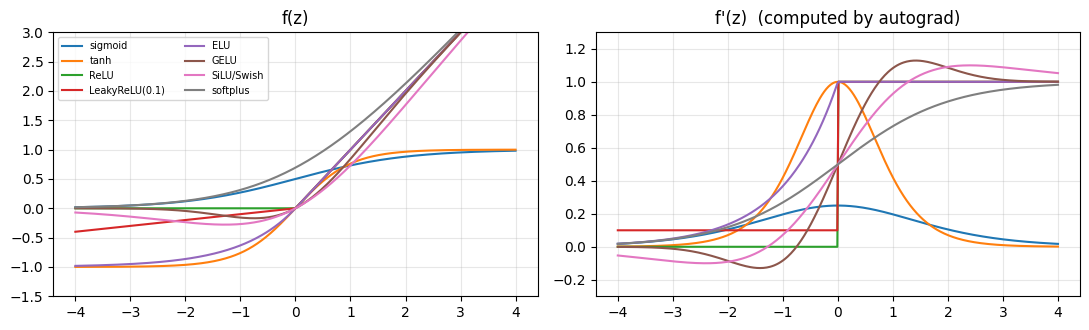

In [16]:
zs = torch.linspace(-4, 4, 400)
acts = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": F.relu, "LeakyReLU(0.1)": lambda z: F.leaky_relu(z, 0.1),
        "ELU": F.elu, "GELU": F.gelu, "SiLU/Swish": F.silu, "softplus": F.softplus}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name, fn in acts.items():
    zz_ = zs.clone().requires_grad_(True); y_ = fn(zz_); y_.sum().backward()      # autograd gives f'(z) for free
    ax[0].plot(zs, y_.detach(), label=name); ax[1].plot(zs, zz_.grad, label=name)
ax[0].set_title("f(z)"); ax[1].set_title("f'(z)  (computed by autograd)"); ax[0].legend(fontsize=7, ncol=2)
for a_ in ax: a_.grid(alpha=.3)
ax[0].set_ylim(-1.5, 3); ax[1].set_ylim(-0.3, 1.3); plt.tight_layout(); plt.show()

| Task | Last layer | Loss module / function | model output shape | target shape and dtype |
|------|-----------|-------------------------|--------------------|------------------------|
| Regression | none (linear) | `nn.MSELoss()` / `F.mse_loss` | `(n,)` or `(n,k)` | **same shape**, float |
| Binary classification | none (logit) | `nn.BCEWithLogitsLoss()` | `(n,)` | `(n,)`, **float** in {0,1} |
| Multi-class | none (logits) | `nn.CrossEntropyLoss()` | `(n,K)` | `(n,)`, **int64** class index |
| Multi-label | none (logits) | `nn.BCEWithLogitsLoss()` | `(n,K)` | `(n,K)`, float in {0,1} |
| Positive outputs | `softplus` | MSE / Poisson NLL | `(n,)` | float |

Never apply `softmax` before `CrossEntropyLoss` or `sigmoid` before `BCEWithLogitsLoss`.

In [17]:
logits = torch.tensor([[2.0, 1.0, 0.1]]); y = torch.tensor([0])
print("correct  CE(logits)        :", F.cross_entropy(logits, y).item())            # 0.417
print("WRONG    CE(softmax(logits)):", F.cross_entropy(logits.softmax(1), y).item())  # softmax applied twice -> different loss
print("by hand  -log softmax[0]   :", -torch.log_softmax(logits, 1)[0, 0].item())

# BCE with logits: float targets, any shape as long as they match
zb, yb = torch.randn(6), torch.randint(0, 2, (6,)).float()
print("BCE:", F.binary_cross_entropy_with_logits(zb, yb).item())
# wrong dtype for labels -> error message you will see
try: F.cross_entropy(logits, torch.tensor([0.0]))
except Exception as e: print("error:", type(e).__name__, str(e)[:70])

# useful options
F.cross_entropy(logits.repeat(4, 1), torch.zeros(4, dtype=torch.long), label_smoothing=0.1)      # label smoothing
F.cross_entropy(logits.repeat(4, 1), torch.zeros(4, dtype=torch.long), reduction="none").shape    # per-example losses
w = torch.tensor([1.0, 2.0, 4.0])                                                                # class weights for imbalance
F.cross_entropy(logits.repeat(4, 1), torch.zeros(4, dtype=torch.long), weight=w);
print("initial-loss sanity: ln(K) for K=10 is", math.log(10))

correct  CE(logits)        : 0.4170299470424652
WRONG    CE(softmax(logits)): 0.8021209239959717
by hand  -log softmax[0]   : 0.4170299470424652
BCE: 0.4342423379421234
error: RuntimeError expected scalar type Long but found Float
initial-loss sanity: ln(K) for K=10 is 2.302585092994046


## 6. Optimisers and schedulers

One step is always: `zero_grad()` $\to$ `forward` $\to$ `loss.backward()` $\to$ (clip) $\to$ `optimizer.step()` $\to$ `scheduler.step()`.

In [18]:
params = list(model.parameters())
sgd      = torch.optim.SGD(params, lr=0.1, momentum=0.9, nesterov=True, weight_decay=0.0)
rmsprop  = torch.optim.RMSprop(params, lr=1e-3, alpha=0.9)
adam     = torch.optim.Adam(params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8)
adamw    = torch.optim.AdamW(params, lr=1e-3, weight_decay=0.05)      # decoupled weight decay: the default for Transformers

# Parameter groups: no weight decay on biases and normalisation parameters (common practice)
decay, no_decay = [], []
for n_, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)                    # biases, LayerNorm gains are 1-D
opt = torch.optim.AdamW([{"params": decay, "weight_decay": 0.05},
                         {"params": no_decay, "weight_decay": 0.0}], lr=1e-3)
print([len(g["params"]) for g in opt.param_groups], "| current lr:", opt.param_groups[0]["lr"])

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\IPython\core\interactiveshell.py", line 2235, in showtraceback
    stb = self.InteractiveTB.structured_traceback(
        etype, value, tb, tb_offset=tb_offset
    )
  File "C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\IPython\core\ultratb.py", line 1272, in structured_traceback
    return FormattedTB.structured_traceback(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        self, etype, evalue, etb, tb_offset, context
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\IPython\core\ultratb.py", line 1138, in structured_traceback
    return VerboseTB.structured_traceback(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        self, etype, evalue, etb, tb_offset, context
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\Admin\AppData\Roaming\Python\Python313

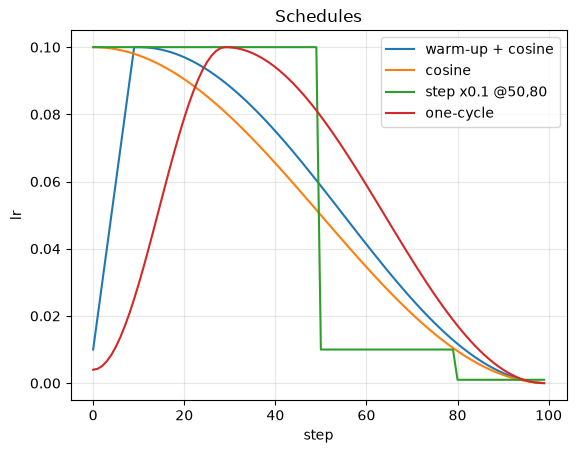

In [ ]:
# Learning-rate schedules. Step the scheduler once PER BATCH for warm-up/cosine-by-step, once per epoch for StepLR etc.
def warmup_cosine(step, warmup, total, min_factor=0.0):
    if step < warmup: return (step + 1) / warmup
    prog = min(max((step - warmup) / max(1, total - warmup), 0.0), 1.0)
    return min_factor + (1 - min_factor) * 0.5 * (1 + math.cos(math.pi * prog))

def lr_trace(make_sched, steps=100, lr=0.1):
    p = nn.Parameter(torch.zeros(1)); o = torch.optim.SGD([p], lr=lr); s = make_sched(o); out = []
    for _ in range(steps): out.append(o.param_groups[0]["lr"]); o.step(); s.step()
    return out
S = torch.optim.lr_scheduler
curves = {
  "warm-up + cosine": lr_trace(lambda o: S.LambdaLR(o, lambda s: warmup_cosine(s, 10, 100))),
  "cosine":           lr_trace(lambda o: S.CosineAnnealingLR(o, T_max=100)),
  "step x0.1 @50,80": lr_trace(lambda o: S.MultiStepLR(o, [50, 80], gamma=0.1)),
  "one-cycle":        lr_trace(lambda o: S.OneCycleLR(o, max_lr=0.1, total_steps=100)),
}
for k, v in curves.items(): plt.plot(v, label=k)
plt.xlabel("step"); plt.ylabel("lr"); plt.grid(alpha=.3); plt.legend(); plt.title("Schedules"); plt.show()
# ReduceLROnPlateau is stepped with a METRIC:  sched.step(val_loss)

In [ ]:
# Gradient clipping: cap the global norm (direction kept). Call between backward() and step().
m = nn.Linear(10, 1); out = (m(torch.randn(32, 10) * 100) ** 2).mean(); out.backward()
total = torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)       # returns the norm BEFORE clipping
print("norm before:", total.item(), "after:", torch.sqrt(sum((p.grad ** 2).sum() for p in m.parameters())).item())

# Gradient accumulation: simulate a big batch with small ones (divide the loss!)
def accumulate_demo(model, opt, batches, accum=4):
    opt.zero_grad(set_to_none=True)
    for i, (xb, yb) in enumerate(batches):
        loss = F.cross_entropy(model(xb), yb) / accum
        loss.backward()                                   # grads add up across micro-batches
        if (i + 1) % accum == 0:
            opt.step(); opt.zero_grad(set_to_none=True)

norm before: 13823.8173828125 after: 0.9999999403953552


## 7. Data: `Dataset` and `DataLoader`

A `Dataset` answers `len(ds)` and `ds[i]`. A `DataLoader` batches, shuffles (new order each epoch) and can load in parallel.
**Split first, then compute normalisation statistics on the training part only.**

315 67 68
torch.Size([32, 2]) torch.float32 torch.Size([32]) torch.int64
torch.Size([4, 2])


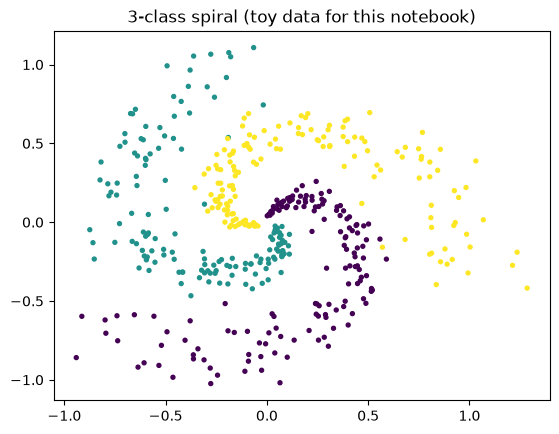

In [ ]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

# In-memory tensors: TensorDataset is enough
def make_spiral(n=150, k=3, noise=0.15, seed=0):
    g = torch.Generator().manual_seed(seed)
    X, y = [], []
    for c in range(k):
        t = torch.linspace(0.05, 1, n); ang = t * 4 + c * 2 * math.pi / k
        X.append(torch.stack([t * torch.sin(ang), t * torch.cos(ang)], 1) + noise * torch.randn(n, 2, generator=g) * t[:, None])
        y.append(torch.full((n,), c))
    return torch.cat(X), torch.cat(y)
X, y = make_spiral()
ds = TensorDataset(X, y)
n_tr, n_va = int(0.7 * len(ds)), int(0.15 * len(ds))
tr_ds, va_ds, te_ds = random_split(ds, [n_tr, n_va, len(ds) - n_tr - n_va], generator=torch.Generator().manual_seed(0))
print(len(tr_ds), len(va_ds), len(te_ds))

g = torch.Generator().manual_seed(0)                       # seeded shuffling -> reproducible batches
tr_loader = DataLoader(tr_ds, batch_size=32, shuffle=True, generator=g, drop_last=False)
va_loader = DataLoader(va_ds, batch_size=128, shuffle=False)     # no shuffle for evaluation
xb, yb = next(iter(tr_loader)); print(xb.shape, xb.dtype, yb.shape, yb.dtype)

# Custom Dataset (e.g. files on disk, augmentation in __getitem__)
class NoisyDataset(Dataset):
    def __init__(self, X, y, sigma=0.05): self.X, self.y, self.sigma = X, y, sigma
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i] + self.sigma * torch.randn_like(self.X[i]), self.y[i]   # augmentation = a regulariser
print(next(iter(DataLoader(NoisyDataset(X, y), batch_size=4)))[0].shape)
# Other knobs: num_workers>0 loads in background processes, pin_memory=True speeds CPU->GPU copies, collate_fn for variable lengths.
plt.scatter(X[:, 0], X[:, 1], c=y, s=8, cmap="viridis"); plt.title("3-class spiral (toy data for this notebook)"); plt.show()

## 8. The training loop (template)

This is the loop of the Week-2 reading, complete with warm-up + cosine schedule, gradient clipping, early stopping on validation loss and
best-weights restore. Copy it, then change one thing at a time.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, loss_fn=F.cross_entropy):
    model.eval()                                                   # dropout off, BN uses running stats
    tot_loss = tot_correct = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        tot_loss += loss_fn(out, yb).item() * len(yb)              # weight by batch size (last batch is smaller)
        tot_correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, tot_correct / n

def train_one_epoch(model, loader, opt, sched=None, loss_fn=F.cross_entropy, clip=None):
    model.train()                                                  # dropout on, BN uses batch stats
    tot_loss = tot_correct = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(set_to_none=True)                            # 1. clear old gradients
        out = model(xb)                                            # 2. forward
        loss = loss_fn(out, yb)                                    # 3. loss (logits in)
        loss.backward()                                            # 4. backward
        if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)  # 5. (optional) clip
        opt.step()                                                 # 6. update
        if sched: sched.step()                                     # 7. per-batch schedule
        tot_loss += loss.item() * len(yb)                          # .item(): a python float (no graph kept alive)
        tot_correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, tot_correct / n

def fit(model, tr_loader, va_loader, opt, epochs, sched=None, clip=None, patience=None, verbose=True):
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best, bad, best_state, best_ep = float("inf"), 0, copy.deepcopy(model.state_dict()), 0
    for ep in range(epochs):
        tl, ta = train_one_epoch(model, tr_loader, opt, sched, clip=clip)
        vl, va = evaluate(model, va_loader)
        for k, v in zip(hist, (tl, ta, vl, va)): hist[k].append(v)
        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            print(f"epoch {ep:3d} | train {tl:.3f} / {ta:.3f} | val {vl:.3f} / {va:.3f} | lr {opt.param_groups[0]['lr']:.2e}")
        if vl < best - 1e-6: best, bad, best_ep, best_state = vl, 0, ep, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience and bad >= patience: print(f"early stop at epoch {ep} (best {best_ep})"); break
    model.load_state_dict(best_state)                              # RESTORE the best weights
    hist["best_epoch"] = best_ep
    return hist

epoch   0 | train 1.019 / 0.451 | val 0.830 / 0.627 | lr 1.65e-03


epoch  10 | train 0.458 / 0.822 | val 0.346 / 0.896 | lr 2.83e-03


epoch  20 | train 0.163 / 0.968 | val 0.093 / 0.985 | lr 2.27e-03


epoch  30 | train 0.108 / 0.975 | val 0.058 / 0.985 | lr 1.50e-03


epoch  40 | train 0.091 / 0.978 | val 0.051 / 0.985 | lr 7.27e-04


epoch  50 | train 0.091 / 0.975 | val 0.046 / 0.985 | lr 1.75e-04


epoch  59 | train 0.080 / 0.984 | val 0.045 / 0.985 | lr 0.00e+00


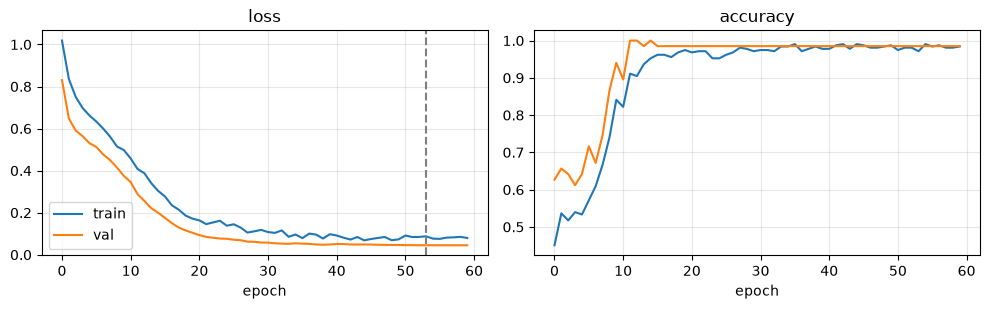

test loss/acc: (0.10501369833946228, 0.9705882352941176)


In [ ]:
set_seed(0)
model = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3))
model.apply(init_he)
epochs, steps = 60, 60 * len(tr_loader)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: warmup_cosine(s, warmup=len(tr_loader) * 2, total=steps))
hist = fit(model, tr_loader, va_loader, opt, epochs, sched, clip=1.0, patience=15)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].axvline(hist["best_epoch"], ls="--", c="gray"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(hist["train_acc"]); ax[1].plot(hist["val_acc"]); ax[1].set_title("accuracy")
for a_ in ax: a_.grid(alpha=.3); a_.set_xlabel("epoch")
plt.tight_layout(); plt.show()
te_loader = DataLoader(te_ds, batch_size=128)
print("test loss/acc:", evaluate(model, te_loader))

tensor([[26,  1,  0],
        [ 0, 19,  0],
        [ 0,  1, 21]])


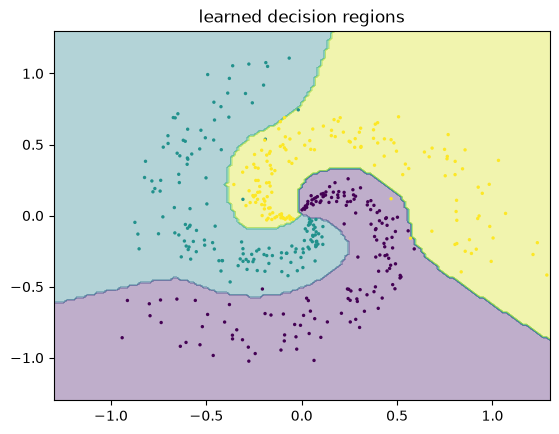

In [ ]:
# Prediction and a confusion matrix (no sklearn needed)
@torch.no_grad()
def predict(model, X):
    model.eval(); return model(X.to(device)).softmax(1)             # softmax ONLY for probabilities at prediction time
Xte = torch.stack([te_ds[i][0] for i in range(len(te_ds))]); yte = torch.stack([te_ds[i][1] for i in range(len(te_ds))])
probs = predict(model, Xte); pred = probs.argmax(1)
K = 3; cm = torch.zeros(K, K, dtype=torch.long)
for t_, p_ in zip(yte, pred): cm[t_, p_] += 1                      # rows = true class, columns = predicted
print(cm)
# Decision regions
gx, gy = torch.meshgrid(torch.linspace(-1.3, 1.3, 150), torch.linspace(-1.3, 1.3, 150), indexing="xy")
grid = torch.stack([gx.flatten(), gy.flatten()], 1)
plt.contourf(gx, gy, predict(model, grid).argmax(1).reshape(150, 150), alpha=.35, cmap="viridis")
plt.scatter(X[:, 0], X[:, 1], c=y, s=6, cmap="viridis", edgecolors="none"); plt.title("learned decision regions"); plt.show()

## 9. Diagnostics: look inside the network

Networks fail silently. These tools find *why* a model does not learn (Week 1 debugging and dead units, Week 2 gradient flow). Healthy training has update/weight ratios around 1e-3 and activations whose std stays stable across layers.

In [ ]:
# (a) Sanity checks BEFORE a long run
set_seed(0)
Xb, yb = next(iter(tr_loader))
fresh = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 3)); fresh.apply(init_he)
print("initial loss:", F.cross_entropy(fresh(Xb), yb).item(), "| expected about ln(3) =", round(math.log(3), 3))

# (b) Overfit ONE batch: loss must reach ~0. If not, there is a bug in model / loss / data.
o = torch.optim.Adam(fresh.parameters(), lr=1e-2)
for i in range(300):
    o.zero_grad(); l = F.cross_entropy(fresh(Xb), yb); l.backward(); o.step()
print("loss after overfitting one batch:", round(l.item(), 5))

initial loss: 1.1659239530563354 | expected about ln(3) = 1.099


loss after overfitting one batch: 0.00793


In [ ]:
# (c) Forward hooks: record what each layer outputs. Always REMOVE hooks afterwards.
def activation_stats(model, X):
    stats, handles = [], []
    for name, m in model.named_modules():
        if isinstance(m, (nn.Linear, nn.ReLU, nn.Tanh, nn.Sigmoid, nn.GELU)):
            handles.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: stats.append((name, type(mod).__name__, out.mean().item(), out.std().item(), (out == 0).float().mean().item()))))
    with torch.no_grad(): model(X)
    for h in handles: h.remove()
    return stats

deep = nn.Sequential(*[l for _ in range(6) for l in (nn.Linear(64, 64), nn.ReLU())], nn.Linear(64, 3))
deep.apply(init_he)
print(f"{'layer':6s}{'type':8s}{'mean':>9s}{'std':>9s}{'zeros':>8s}")
for name, typ, mu, sd, z0 in activation_stats(deep, torch.randn(256, 64)): print(f"{name:6s}{typ:8s}{mu:9.3f}{sd:9.3f}{z0:8.2f}")

layer type         mean      std   zeros
0     Linear      0.002    1.429    0.00
1     ReLU        0.570    0.830    0.50
2     Linear     -0.042    1.432    0.00
3     ReLU        0.543    0.837    0.52
4     Linear      0.028    1.326    0.00
5     ReLU        0.537    0.762    0.48
6     Linear      0.014    1.262    0.00
7     ReLU        0.503    0.758    0.51
8     Linear      0.078    1.329    0.00
9     ReLU        0.558    0.831    0.48
10    Linear      0.068    1.237    0.00
11    ReLU        0.521    0.747    0.48
12    Linear     -1.707    0.983    0.00


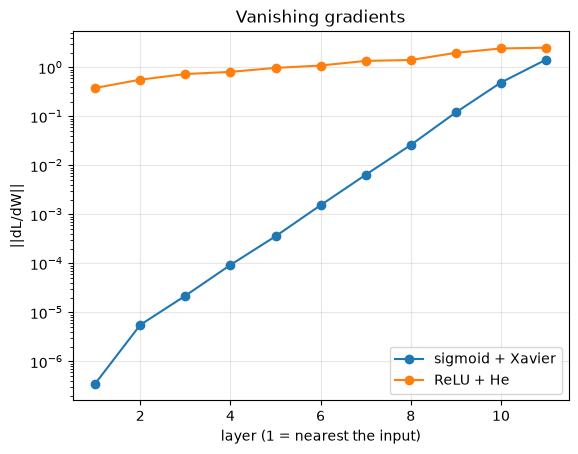

update/weight ratio: 4.2074094380950555e-05


In [ ]:
# (d) Gradient norms per layer: vanishing (tiny near the input) or exploding (huge). Compare inits.
def grad_norms(model, X, y):
    model.zero_grad(set_to_none=True)
    F.cross_entropy(model(X), y).backward()
    return [m.weight.grad.norm().item() for m in model if isinstance(m, nn.Linear)]

def make_deep(act, depth=10, width=64):
    return nn.Sequential(*[l for _ in range(depth) for l in (nn.Linear(width, width), act())], nn.Linear(width, 3))
Xd, yd = torch.randn(256, 64), torch.randint(0, 3, (256,))
res = {}
for name, act, init in [("sigmoid + Xavier", nn.Sigmoid, init_xavier), ("ReLU + He", nn.ReLU, init_he)]:
    set_seed(0); mdl = make_deep(act); mdl.apply(init); res[name] = grad_norms(mdl, Xd, yd)
for k, v in res.items(): plt.semilogy(range(1, len(v) + 1), v, marker="o", label=k)
plt.xlabel("layer (1 = nearest the input)"); plt.ylabel("||dL/dW||"); plt.legend(); plt.grid(alpha=.3); plt.title("Vanishing gradients"); plt.show()

# (e) Backward hooks / retain_grad give gradients of ACTIVATIONS; parameter update ratio ~1e-3 is a healthy rule of thumb
p = deep[0].weight; lr = 1e-3
F.cross_entropy(deep(Xd[:, :64]), yd).backward()
print("update/weight ratio:", (lr * p.grad.norm() / p.norm()).item())

has nan: True | all finite: False
grad at sqrt(0): tensor([inf])


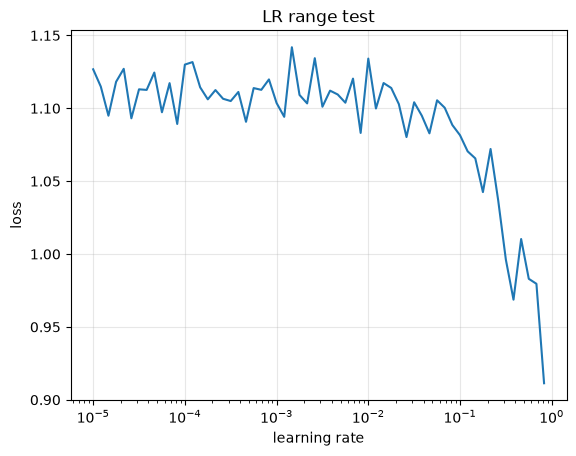

In [ ]:
# (f) NaN / Inf hunting
t = torch.tensor([1.0, float("nan")])
print("has nan:", torch.isnan(t).any().item(), "| all finite:", torch.isfinite(t).all().item())
# torch.autograd.set_detect_anomaly(True) makes backward raise at the op that produced a NaN (slow: debug only)
try:
    with torch.autograd.set_detect_anomaly(True):
        a = torch.tensor([0.0], requires_grad=True); torch.sqrt(a).sum().backward(); print("grad at sqrt(0):", a.grad)
except Exception as e: print("anomaly:", type(e).__name__)
# Typical causes of NaN loss: learning rate too high, log(0) or division by 0, exploding gradients (clip!), fp16 overflow.
# (g) Learning-rate range test: run a few steps with lr growing exponentially and plot loss vs lr; pick lr a bit below the minimum.
def lr_range_test(make_model, loader, lr_min=1e-5, lr_max=1.0, steps=60):
    m = make_model(); o = torch.optim.SGD(m.parameters(), lr=lr_min); gam = (lr_max / lr_min) ** (1 / steps)
    lrs, losses, it = [], [], iter(loader)
    for _ in range(steps):
        try: xb, yb = next(it)
        except StopIteration: it = iter(loader); xb, yb = next(it)
        o.zero_grad(); l = F.cross_entropy(m(xb), yb); l.backward(); o.step()
        lrs.append(o.param_groups[0]["lr"]); losses.append(l.item())
        for g_ in o.param_groups: g_["lr"] *= gam
    return lrs, losses
lrs, ls = lr_range_test(lambda: nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 3)), tr_loader)
plt.semilogx(lrs, ls); plt.xlabel("learning rate"); plt.ylabel("loss"); plt.grid(alpha=.3); plt.title("LR range test"); plt.show()

## 10. Speed and devices

In [ ]:
# Move BOTH model and data to the same device; keep loss scalars as Python floats with .item()
model = model.to(device)
xb, yb = Xb.to(device), yb.to(device)               # a matching (inputs, labels) batch from Section 9
print("model on", next(model.parameters()).device, "| data on", xb.device)

# inference_mode is a faster no_grad for pure inference
with torch.inference_mode(): _ = model(xb)

# Mixed precision (GPU): autocast runs ops in bf16/fp16; GradScaler guards fp16 against gradient underflow
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
def amp_step(model, opt, xb, yb):
    opt.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        loss = F.cross_entropy(model(xb), yb)
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)             # clip AFTER unscale
    scaler.step(opt); scaler.update(); return loss.item()
print("amp step loss:", amp_step(copy.deepcopy(model), torch.optim.AdamW(model.parameters(), 1e-3), xb, yb))   # on a copy: keeps `model` unchanged

# Timing: on GPU call torch.cuda.synchronize() before reading the clock (kernels are asynchronous)
A_ = torch.randn(1024, 1024, device=device)
t0 = time.perf_counter()
for _ in range(20): _ = A_ @ A_
if device.type == "cuda": torch.cuda.synchronize()
print(f"20 matmuls (1024x1024): {time.perf_counter() - t0:.3f}s on {device}")
# torch.compile(model) can speed up training on recent GPUs (PyTorch 2.x); channels/batch size multiples of 8 help tensor cores.

model on cpu | data on cpu
amp step loss: 0.052023325115442276


20 matmuls (1024x1024): 0.172s on cpu


**CPU threads for tiny models.** PyTorch uses all cores for each operation. For *small* networks (like the homework MLPs) the synchronisation costs more than the arithmetic, and training can become
**orders of magnitude slower** on a many-core machine. If your CPU training is mysteriously slow, try `torch.set_num_threads(1)` (or 2-4). Large models and GPUs are different.

In [ ]:
def ten_steps(threads):
    torch.set_num_threads(threads)
    m = nn.Sequential(*[l for _ in range(10) for l in (nn.Linear(64, 64), nn.ReLU())], nn.Linear(64, 10))
    o = torch.optim.SGD(m.parameters(), lr=0.01); xb, yb = torch.randn(64, 64), torch.randint(0, 10, (64,))
    t0 = time.perf_counter()
    for _ in range(10): o.zero_grad(); F.cross_entropy(m(xb), yb).backward(); o.step()
    return time.perf_counter() - t0
default_threads = torch.get_num_threads()
print(f"1 thread: {ten_steps(1):.4f}s | {default_threads} threads: {ten_steps(default_threads):.4f}s  (10 training steps of a tiny MLP)")
torch.set_num_threads(1)

1 thread: 0.0092s | 16 threads: 1.3289s  (10 training steps of a tiny MLP)


## 11. Saving and loading

In [ ]:
import os, tempfile
path = os.path.join(tempfile.gettempdir(), "ckpt.pt")
# Save the state_dict (weights), not the whole pickled model. For resuming training also save optimiser/scheduler/epoch.
torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": 12, "val_loss": hist["val_loss"][-1]}, path)

ckpt = torch.load(path, map_location=device)                      # map_location lets a GPU checkpoint load on CPU
fresh_model = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3)).to(device)
fresh_model.load_state_dict(ckpt["model"])                         # architecture must match
fresh_model.eval()
print("restored test acc:", evaluate(fresh_model, te_loader)[1], "| resumed from epoch", ckpt["epoch"])

restored test acc: 0.9705882352941176 | resumed from epoch 12


## 12. Reproducibility

Same seed $\Rightarrow$ same numbers on the same machine. Seed Python, NumPy and PyTorch, give the `DataLoader` a seeded `generator`, and
create a separate `torch.Generator` for anything you sample inside the code (splits, mixup).

In [ ]:
def run_once(seed):
    set_seed(seed)
    m = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 3))
    ld = DataLoader(tr_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(seed))
    o = torch.optim.SGD(m.parameters(), lr=0.1)
    for xb, yb in ld:
        o.zero_grad(); F.cross_entropy(m(xb), yb).backward(); o.step()
    return F.cross_entropy(m(Xte), yte).item()
print(run_once(1), run_once(1), run_once(2))     # first two are identical
# Stricter (slower): torch.use_deterministic_algorithms(True). For multi-worker loaders also pass worker_init_fn.
# Different seeds: report mean +/- std over several seeds before claiming that one method beats another.

1.073922038078308 1.073922038078308 1.1046425104141235


## 13. Common errors and fixes

| Symptom / message | Usual cause | Fix |
|-------------------|-------------|-----|
| `mat1 and mat2 shapes cannot be multiplied` | wrong `in_features`, forgot to flatten | print `x.shape`; `x.flatten(1)`; match `nn.Linear(in, out)` |
| `expected scalar type Long but found Float` (or reverse) | label dtype wrong for the loss | CE: `y.long()`; BCE/MSE: `y.float()` |
| loss is a **silent** wrong number, no error | `(n,)` vs `(n,1)` broadcast, softmax before CE | check shapes; feed logits |
| `Trying to backward through the graph a second time` | reusing a graph (storing tensors with graph in a list) | `loss.item()`, `.detach()`; recompute the forward |
| `one of the variables needed for gradient computation has been modified by an inplace operation` | `x += 1`, `relu_` on a needed tensor | use out-of-place ops |
| `element 0 of tensors does not require grad` | wrapped in `no_grad`, or `detach()`ed, or all params frozen | check `requires_grad`, remove `no_grad` from training |
| training loss falls, val loss rises | overfitting | weight decay, dropout, augmentation, early stopping, more data |
| loss does not move at all | lr far too small/large, forgot `opt.step()`, dead ReLUs, wrong init, labels shuffled apart from inputs | overfit one batch; print grad norms; lr range test |
| loss becomes `nan` after some steps | lr too high, log(0), exploding gradients | lower lr, clip gradients, use `*_with_logits`, check data for NaN |
| val accuracy jumps around / differs between runs | `model.eval()` missing (dropout/BN on) | `model.eval()` + `torch.no_grad()` in evaluation |
| `Expected all tensors to be on the same device` | model on GPU, data on CPU | `.to(device)` on both |
| memory grows every step | accumulating `loss` (a tensor with graph) | `total += loss.item()` |
| gradients are `None` | tensor not a leaf / not used in the loss / frozen | `retain_grad()`, check the graph path |

In [ ]:
# Reproduce the two most common ones on purpose, so you recognise them:
try: nn.Linear(10, 5)(torch.randn(4, 8))
except RuntimeError as e: print("1)", str(e)[:75])
try: F.cross_entropy(torch.randn(4, 3), torch.tensor([0., 1., 2., 0.]))
except Exception as e: print("2)", type(e).__name__, "-", str(e)[:75])

1) mat1 and mat2 shapes cannot be multiplied (4x8 and 10x5)
2) RuntimeError - expected target dtype to be Long or Byte, but got Float


## 14. Quick reference

| Goal | Code |
|------|------|
| Seed | `torch.manual_seed(0)` (+ `random`, `numpy`) |
| Shape / dtype | `x.shape`, `x.dtype`, `x.float()`, `y.long()` |
| Flatten batch | `x.flatten(1)` or `x.view(x.size(0), -1)` |
| One-hot | `F.one_hot(y, K).float()` |
| Normalise | `(X - mu) / (sd + 1e-8)` with **train** `mu`, `sd` |
| Linear layer | `nn.Linear(in, out)`: `W` has shape `(out, in)` |
| Parameter count | `sum(p.numel() for p in m.parameters())` |
| He / Xavier init | `nn.init.kaiming_normal_(w, nonlinearity="relu")` / `nn.init.xavier_normal_(w)` |
| Loss (multi-class) | `F.cross_entropy(logits, y_long)` |
| Loss (binary) | `F.binary_cross_entropy_with_logits(z, y_float)` |
| One training step | `opt.zero_grad(); loss.backward(); clip; opt.step(); sched.step()` |
| Eval | `model.eval()` + `with torch.no_grad():` |
| Accuracy | `(logits.argmax(1) == y).float().mean().item()` |
| Optimiser | `torch.optim.AdamW(params, lr=1e-3, weight_decay=0.05)` |
| Warm-up + cosine | `LambdaLR(opt, lambda s: warmup_cosine(s, warm, total))` |
| Clip gradients | `nn.utils.clip_grad_norm_(model.parameters(), 1.0)` |
| Gradient check | `torch.autograd.gradcheck(f, (x_double_requires_grad,))` |
| Hooks | `h = m.register_forward_hook(fn)`; `h.remove()` |
| Save / load weights | `torch.save(m.state_dict(), p)`; `m.load_state_dict(torch.load(p, map_location=dev))` |
| Device | `m.to(dev)`, `x.to(dev)` |

**Debug order when training fails:** (1) shapes and dtypes, (2) initial loss $\approx\ln K$, (3) overfit one batch, (4) learning rate (range test),
(5) gradient/activation statistics, (6) `train()`/`eval()` and data leakage, (7) only then change the model.